# Предобработка данных и регрессия на датасете «House Prices»

## Титульный лист

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 2:** Предобработка данных и базовые алгоритмы регрессии/классификации  
**Датасет:** *House Prices — Advanced Regression Techniques*

**Выполнил:** Белозёров Константин Сергеевич  
**Группа:** ПКТб-23-1  
**Преподаватель:** не указан в задании

**Ссылка на репозиторий:** https://github.com/Pankyxa/ml-course-Belozyorov  
**Путь к модулю:** `module-2-house-prices/notebook.ipynb`  
**Дата сдачи:** 2026-11-02

*Ноутбук подготовлен с помощью ИИ-ассистента Cursor. Метрики посчитаны локально на `train.csv`.*


## Введение

**Задача.** Нужно предсказать цену продажи дома в Эймсе. Ответ — непрерывная сумма в долларах, от примерно 35 тысяч до 755 тысяч, а не метка класса.

**ML-проект для регрессии.** Сначала смотрят, где пустые поля и где цена «сломана» выбросом. Потом выравнивают скошенную цель, собирают площадь и возраст дома в отдельные признаки, обучают несколько линейных моделей и проверяют их на домах, которые модель не видела. В конце коэффициенты переводят обратно в деньги: на сколько долларов ошибается прогноз.

**Почему это регрессия, а не классификация.** Классификация выбирает категорию: выжил или нет, уйдёт клиент или нет. Здесь ошибка измеряется в долларах. Предсказать 180 тысяч вместо 200 тысяч — это промах на 20 тысяч, а не «не тот класс». Поэтому модель выдаёт число, а качество считают через RMSE, MAE и R².

**Какая метрика важнее.** RMSE штрафует крупные промахи сильнее, чем MAE: для риелтора ошибка на 80 тысяч больнее, чем десять ошибок по 8 тысяч. R² показывает, какую долю разброса цен модель вообще объяснила. В этой работе главная цель — **R² ≥ 0.90** на логарифме цены, а RMSE в долларах остаётся рядом, чтобы ошибку было видно в деньгах.

**Цель работы:**

1. Провести полный EDA датасета House Prices.
2. Обучить 4 модели (Linear, Ridge, Lasso, ElasticNet) и достичь R² ≥ 0.90.
3. Реализовать функцию `predict_price` для нового дома.


## Теоретическая часть

### Регрессия

Регрессия предсказывает число: цену, спрос, время в пути. Классификация предсказывает метку из конечного списка. У дома нет «класса цены», который был бы зашит в данных заранее: 163 тысячи и 170 тысяч — соседние ответы, и модель должна это чувствовать. Линейная регрессия складывает признаки с весами и выдаёт одно число. Если цель прологарифмирована, это число сначала живёт в логарифмах, а в доллары его возвращают через `expm1`. Так ошибка в дорогом доме и в дешёвом не измеряется одной и той же линейкой.

### Пропуски

Пустая ячейка бывает трёх сортов. MCAR — значение потеряли случайно, без связи с домом. MAR — пропуск зависит от других столбцов, которые мы видим: у домов без гаража пустой `GarageType`. MNAR — сама причина пропуска связана с тем, чего мы не записали. В Ames большинство «дыр» в гараже, подвале и бассейне — это MAR: признака нет, потому что объекта нет. Такие поля заполняются строкой `"None"` или нулём. `LotFrontage` скорее зависит от района, поэтому медиана берётся внутри `Neighborhood`, а не по всей таблице.

### Регуляризация

Обычная регрессия на двухстах дамми-столбцах легко подгоняет шум: соседние районы начинают спорить друг с другом. **Ridge (L2)** добавляет к ошибке сумму квадратов весов и уменьшает их, не обнуляя. Это как раз случай мультиколлинеарности, когда площадь первого этажа и общая площадь говорят почти одно и то же. **Lasso (L1)** добавляет сумму модулей и может поставить вес ровно в ноль, то есть выкинуть признак. **ElasticNet** смешивает оба штрафа: часть столбцов обнуляется, остальные сжимаются. Параметр `alpha` — сила штрафа, `l1_ratio` — доля L1.

### Логарифмирование

У `SalePrice` длинный правый хвост: много домов около 150–180 тысяч и горстка очень дорогих. Среднеквадратичная ошибка тогда почти целиком состоит из этих дорогих точек. `log1p` сжимает хвост и делает распределение ближе к симметричному. `log1p`, а не `log`, потому что формула определена и в нуле: \(\log(1+x)\). Обратный переход — `expm1`. Метрики R² и RMSE ниже считаются и в логарифмах, и в долларах.

### Feature Engineering

Сырые столбцы не всегда совпадают с тем, как цену называют люди. «Большой дом» — это подвал плюс оба этажа, а не только `GrLivArea`. «Сколько ванных» — полные плюс половина полуванных, включая подвал. Возраст — это `YrSold - YearBuilt`, а не сам год постройки: год сам по себе растёт вместе с инфляцией. Бинарные флаги бассейна и гаража отделяют «объекта нет» от его размера. Произведение качества на площадь ловит ситуацию, в которой хороший большой дом стоит дороже, чем сумма двух эффектов по отдельности.

### Метрики регрессии

$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

$$RMSE = \sqrt{MSE} \quad MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

MSE — средний квадрат промаха, в долларах он неудобен из-за квадрата. RMSE возвращает ту же единицу, что у цели: доллары или логарифм. MAE — средний модуль, он спокойнее относится к одному странному особняку. R² = 1, если прогноз совпал с фактом, R² = 0, если модель не лучше константы «предскажи среднюю цену». Отрицательный R² значит, что константа была бы честнее.

| Модель | Штраф | Что делает с лишними признаками |
|--------|--------|----------------------------------|
| Linear Regression | нет | оставляет все веса |
| Ridge | L2 | уменьшает веса, почти не обнуляет |
| Lasso | L1 | может обнулить вес |
| ElasticNet | L1 + L2 | обнуляет часть и сжимает остальные |


## Описание данных

**Источник:** [House Prices — Advanced Regression Techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques)

**Структура:**

- Всего примеров в train: 1460
- Всего примеров в test: 1459
- Признаков: 79 (+ `Id` + целевая `SalePrice`)
- Числовых признаков: 36
- Категориальных признаков: 43

| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| Id | int | Идентификатор дома, в модель не входит | 0% |
| SalePrice | float | Целевая: цена продажи, $ | 0% |
| OverallQual | int 1–10 | Общее качество материалов и отделки | 0% |
| GrLivArea | int | Жилая площадь над землёй, кв. футы | 0% |
| TotalBsmtSF | int | Площадь подвала | 0% |
| YearBuilt | int | Год постройки | 0% |
| GarageCars | int | Сколько машин входит в гараж | 0% |
| LotFrontage | float | Длина фасада, футы | около 17% |
| GarageType | object | Тип гаража. Пусто обычно значит «гаража нет» | около 6% |
| PoolQC | object | Качество бассейна | около 99.5% |
| Neighborhood | object | Район | 0% |

**Распределение целевой:**

- Среднее: $180 921
- Медиана: $163 000
- Асимметрия (skew): 1.88 — правое смещение
- Эксцесс: 6.54

**Файл данных в репозитории:** `module-2-house-prices/data/house_prices_info.md`

Тестовый файл Kaggle не содержит `SalePrice`, поэтому качество считается на отложенных 20% обучающей выборки. Код ниже сверяет размеры.


In [1]:
%matplotlib inline

# Таблицы, графики, модели и сохранение
import json
import time
from io import BytesIO
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Общий вид графиков
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False

# Пути относительно папки module-2-house-prices
train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')
# Форма обеих таблиц — обязательная проверка
print(train_df.shape, test_df.shape)
print('skew SalePrice:', round(train_df['SalePrice'].skew(), 3))
print('kurtosis SalePrice:', round(train_df['SalePrice'].kurtosis(), 3))
print('mean / median:', round(train_df['SalePrice'].mean()), '/', round(train_df['SalePrice'].median()))


Matplotlib is building the font cache; this may take a moment.


(1460, 81) (1459, 80)
skew SalePrice: 1.883
kurtosis SalePrice: 6.536
mean / median: 180921 / 163000


## Подготовка данных и EDA

Сначала таблица осматривается как есть: типы, пропуски, форма цены. Графики строятся до заполнения пустых значений и до удаления двух странных домов, чтобы выброс на диаграмме рассеяния был виден. Чистка и новые признаки идут следующим блоком.


In [2]:
# Первые строки и сводка по числам
display(train_df.head())
train_df.info()
display(train_df.describe().T.head(12))

# Пропуски: абсолютное число и доля
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df) * 100).round(2)
missing_table = pd.DataFrame({'пропуски': missing, 'доля_%': missing_pct})
missing_table = missing_table[missing_table['пропуски'] > 0].sort_values('доля_%', ascending=False)
display(missing_table.head(15))


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


,пропуски,доля_%
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


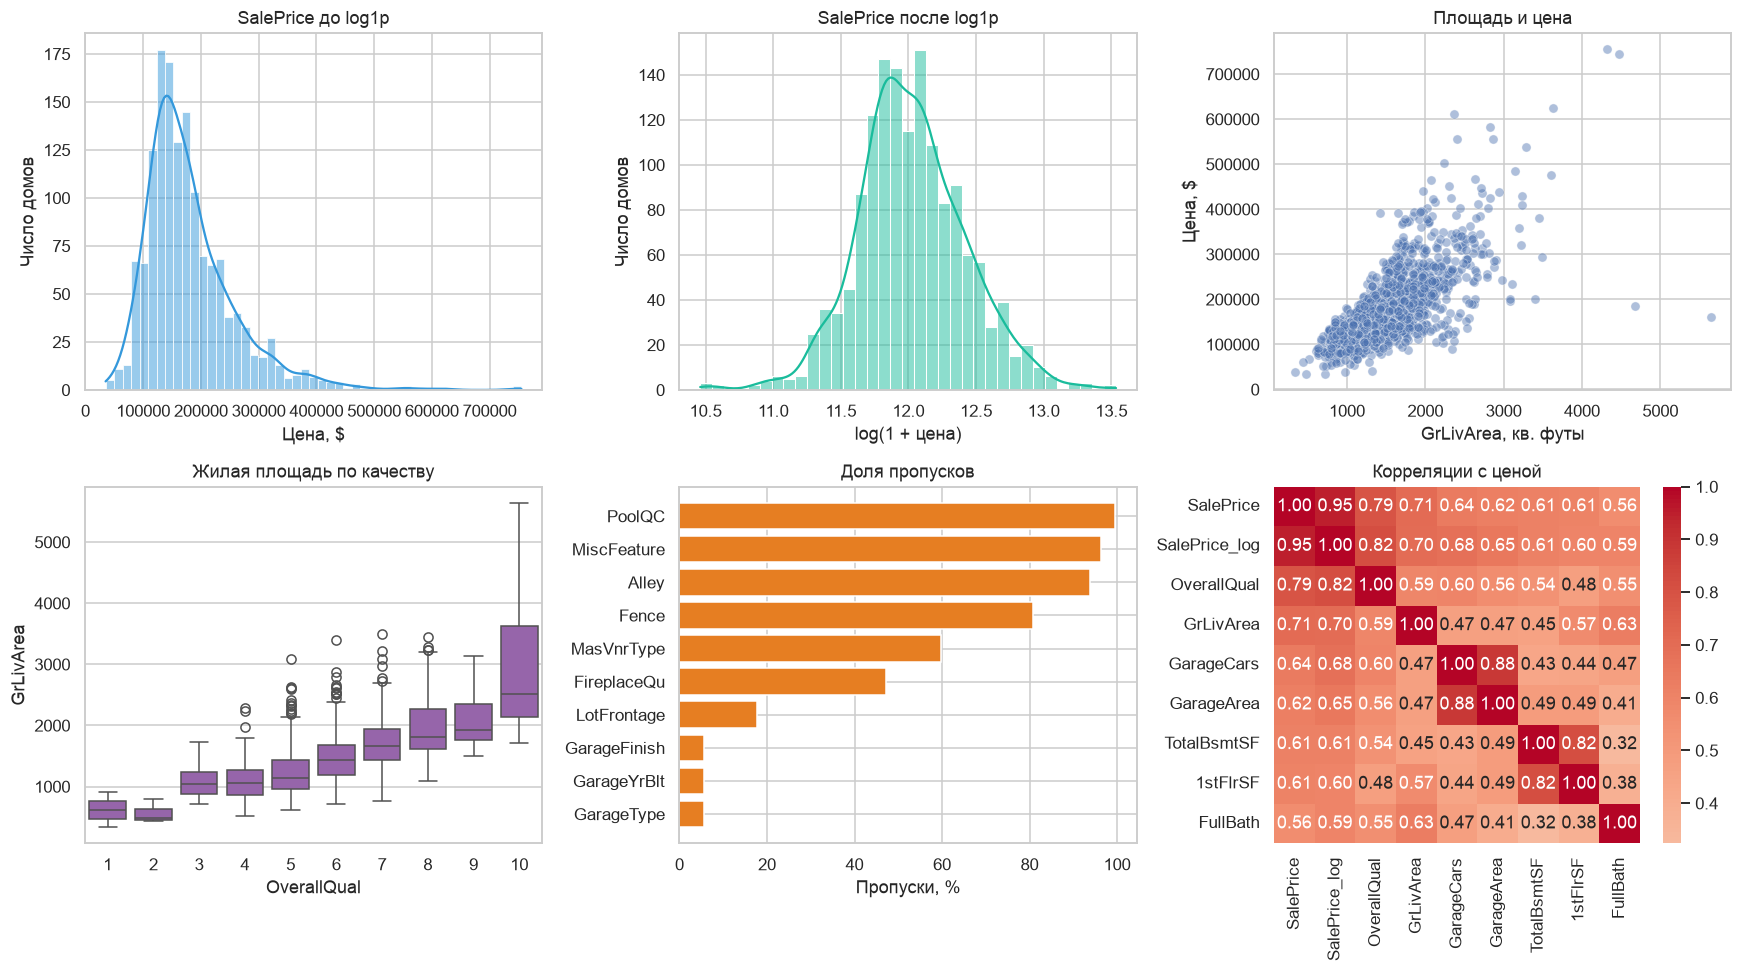

Сильнее всего с ценой связаны: SalePrice_log, OverallQual, GrLivArea, GarageCars, GarageArea


In [3]:
# Логарифм цены нужен и для картинки, и позже для обучения
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# 1. Сырая цена тянется вправо
sns.histplot(data=train_df, x='SalePrice', kde=True, ax=axes[0, 0], color='#3498db')
axes[0, 0].set_title('SalePrice до log1p')
axes[0, 0].set_xlabel('Цена, $')
axes[0, 0].set_ylabel('Число домов')

# 2. После логарифма распределение ближе к симметричному
sns.histplot(data=train_df, x='SalePrice_log', kde=True, ax=axes[0, 1], color='#1abc9c')
axes[0, 1].set_title('SalePrice после log1p')
axes[0, 1].set_xlabel('log(1 + цена)')
axes[0, 1].set_ylabel('Число домов')

# 3. Связь жилой площади и цены. Две точки справа и внизу — частичные продажи
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', ax=axes[0, 2], alpha=0.45)
axes[0, 2].set_title('Площадь и цена')
axes[0, 2].set_xlabel('GrLivArea, кв. футы')
axes[0, 2].set_ylabel('Цена, $')

# 4. Качество отделки против площади
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', ax=axes[1, 0], color='#9b59b6')
axes[1, 0].set_title('Жилая площадь по качеству')
axes[1, 0].set_xlabel('OverallQual')
axes[1, 0].set_ylabel('GrLivArea')

# 5. Самые дырявые столбцы
top_missing = missing_table.head(10).sort_values('доля_%')
axes[1, 1].barh(top_missing.index, top_missing['доля_%'], color='#e67e22')
axes[1, 1].set_title('Доля пропусков')
axes[1, 1].set_xlabel('Пропуски, %')

# 6. Корреляции признаков, которые сильнее всего связаны с ценой
num_corr = train_df.select_dtypes(include='number').corr()['SalePrice'].drop('SalePrice').abs().sort_values(ascending=False)
heat_cols = ['SalePrice'] + num_corr.head(8).index.tolist()
sns.heatmap(train_df[heat_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 2])
axes[1, 2].set_title('Корреляции с ценой')

fig.tight_layout()
Path('examples').mkdir(exist_ok=True)
fig.savefig('examples/eda_plots.png', bbox_inches='tight')
plt.show()
print('Сильнее всего с ценой связаны:', ', '.join(num_corr.head(5).index))


### Что видно на графиках

- Сырая цена скошена вправо: среднее $180 921 выше медианы $163 000, skew около 1.88. После `log1p` горб становится почти симметричным, поэтому учить модель выгоднее на логарифме.
- `OverallQual` и `GrLivArea` — самые сильные линейные спутники цены. Качество 9–10 в среднем уходит далеко за 350 тысяч, качество 1–3 остаётся около 50–90 тысяч.
- На диаграмме площади есть дома больше 4000 кв. футов с ценой ниже 300 тысяч. Это не «огромный дешёвый дворец», а частичные продажи. Они ломают прямую и их нужно убрать отдельно от обычных больших домов.
- Верхняя граница IQR для `GrLivArea` — около 2748 кв. футов, за неё выходит 31 дом. Среди них много настоящих дорогих домов. Резать весь этот хвост нельзя: вместе с мусором уйдёт сигнал «большая площадь стоит дороже». Удаляются только две точки, которые одновременно огромные и неправдоподобно дешёвые.
- Пропуски собраны в признаках, которых у дома может не быть: бассейн, переулок, забор, камин, гараж, подвал. Это не случайно потерянные числа.


In [4]:
# Копия, чтобы графики выше остались на сырых данных
work = train_df.drop(columns=['SalePrice_log']).copy()

# IQR считаем и показываем, но не режем им все большие дома
q1, q3 = work['GrLivArea'].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
print('Верхний ус IQR для GrLivArea:', round(upper_fence, 1))
print('Домов за усом:', int((work['GrLivArea'] > upper_fence).sum()))

# Две частичные продажи: огромная площадь и цена не соответствует
domain_out = (work['GrLivArea'] > 4000) & (work['SalePrice'] < 300_000)
print('Удаляем по доменному правилу:', int(domain_out.sum()))
work = work.loc[~domain_out].copy()

# Пустое качество объекта, которого нет, — отдельная категория, не «забыли записать»
none_cols = [
    'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType',
]
for col in none_cols:
    work[col] = work[col].fillna('None')

# Нет гаража или подвала — площадь и число машин равны нулю
zero_cols = [
    'GarageYrBlt', 'GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2',
    'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea',
]
for col in zero_cols:
    work[col] = work[col].fillna(0)

# Фасад зависит от района, поэтому медиана локальная
work['LotFrontage'] = work.groupby('Neighborhood')['LotFrontage'].transform(lambda s: s.fillna(s.median()))
work['Electrical'] = work['Electrical'].fillna(work['Electrical'].mode().iloc[0])

# Ручной порядок для оценок Ex/Gd/TA/Fa/Po
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
for col in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']:
    work[col] = work[col].map(qual_map).fillna(0)
work['BsmtExposure'] = work['BsmtExposure'].map({'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}).fillna(0)
for col in ['BsmtFinType1', 'BsmtFinType2']:
    work[col] = work[col].map({'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}).fillna(0)
work['GarageFinish'] = work['GarageFinish'].map({'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}).fillna(0)
work['Functional'] = work['Functional'].map({'Sal': 1, 'Sev': 2, 'Maj2': 3, 'Maj1': 4, 'Mod': 5, 'Min2': 6, 'Min1': 7, 'Typ': 8}).fillna(8)
work['Fence'] = work['Fence'].map({'None': 0, 'MnWw': 1, 'GdWo': 2, 'MnPrv': 3, 'GdPrv': 4}).fillna(0)
work['LotShape'] = work['LotShape'].map({'IR3': 1, 'IR2': 2, 'IR1': 3, 'Reg': 4})
work['PavedDrive'] = work['PavedDrive'].map({'N': 0, 'P': 1, 'Y': 2})
work['CentralAir'] = (work['CentralAir'] == 'Y').astype(int)

# Новые признаки: площадь, ванные, возраст, флаги
work['TotalSF'] = work['TotalBsmtSF'] + work['1stFlrSF'] + work['2ndFlrSF']
work['TotalBath'] = work['FullBath'] + 0.5 * work['HalfBath'] + work['BsmtFullBath'] + 0.5 * work['BsmtHalfBath']
work['TotalPorch'] = work['OpenPorchSF'] + work['EnclosedPorch'] + work['3SsnPorch'] + work['ScreenPorch'] + work['WoodDeckSF']
work['HouseAge'] = work['YrSold'] - work['YearBuilt']
work['RemodAge'] = work['YrSold'] - work['YearRemodAdd']
work['HasPool'] = (work['PoolArea'] > 0).astype(int)
work['HasGarage'] = (work['GarageArea'] > 0).astype(int)
work['Has2ndFloor'] = (work['2ndFlrSF'] > 0).astype(int)
work['HasFireplace'] = (work['Fireplaces'] > 0).astype(int)
work['OverallQual_TotalSF'] = work['OverallQual'] * work['TotalSF']
work['SalePrice_log'] = np.log1p(work['SalePrice'])
# Класс здания — код, а не величина «чем больше, тем лучше»
work['MSSubClass'] = work['MSSubClass'].astype(str)

# Оставшиеся номинальные столбцы
obj_cols = [c for c in work.columns if pd.api.types.is_string_dtype(work[c])]
for col in obj_cols:
    work[col] = work[col].fillna(work[col].mode().iloc[0])
work = pd.get_dummies(work, columns=obj_cols, drop_first=True)

# Логарифм сильно скошенных неотрицательных чисел, кроме уже собранного произведения
feature_before_log = [c for c in work.columns if c not in ['Id', 'SalePrice', 'SalePrice_log']]
logged_cols = []
for col in feature_before_log:
    if col == 'OverallQual_TotalSF':
        continue
    series = work[col]
    if pd.api.types.is_numeric_dtype(series) and series.min() >= 0 and abs(series.skew()) > 0.75:
        work[col] = np.log1p(series)
        logged_cols.append(col)
print('Прологарифмировано признаков:', len(logged_cols))

feature_cols = [c for c in work.columns if c not in ['Id', 'SalePrice', 'SalePrice_log']]
X = work[feature_cols].astype(float).fillna(0)
y = work['SalePrice_log']
print('Матрица признаков:', X.shape, 'пропусков:', int(X.isnull().sum().sum()))


Верхний ус IQR для GrLivArea: 2747.6
Домов за усом: 31
Удаляем по доменному правилу: 2
Прологарифмировано признаков: 191
Матрица признаков: (1458, 225) пропусков: 0


### Почему обработка именно такая

- **Смысловые пропуски** (`PoolQC`, `GarageType`, `BsmtQual` и соседние) заменены на `"None"` или 0. Пустая каюта бассейна почти у всех домов означает «бассейна нет», а не «качество неизвестно». Если подставить сюда моду, модель решит, что у дома обычный бассейн.
- **`LotFrontage`** заполнен медианой района. Длина фасада в центре и на окраине разная, общая медиана это сотрёт.
- **`Electrical`** — один редкий пропуск, хватает моды.
- **Выбросы.** IQR показывает 31 большой дом, но удаляются только 2 частичные продажи (`GrLivArea > 4000` и цена ниже $300 000). Остальные большие дома — настоящие дорогие объекты.
- **`log1p` цели** нужен из-за skew 1.88. Тот же приём применён к сильно скошенным признакам вроде площади, чтобы линейная модель не училась на одном хвосте.
- **Порядковые оценки** закодированы руками от `None=0` до `Ex=5`. Район, тип продажи и стиль дома разложены в дамми без базового уровня, чтобы не дублировать свободный член.


## Построение и обучение моделей

Четыре обязательные модели учатся на одной и той же матрице после `StandardScaler`. Лес добавлен как бонус и масштаб не использует: ему важен порядок значений, а не «сколько сигм».

| Модель | Параметры | Масштабирование |
|--------|-----------|-----------------|
| Linear Regression | без штрафа | да |
| Ridge | alpha=1.0 | да |
| Lasso | alpha=0.0005 | да |
| ElasticNet | alpha=0.001, l1_ratio=0.5 | да |
| Random Forest | 300 деревьев, глубина 12 | нет |

Цель — `SalePrice_log`. Разбиение 80/20, `random_state=42`. Scaler учится только на обучающих 80%.


In [5]:
# Отложенная выборка. В тесте Kaggle цены нет, поэтому держим свои 20%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Обучение:', len(X_train), 'тест:', len(X_test))

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LinearRegression()
start = time.time()
lr_model.fit(X_train_scaled, y_train)
lr_time = time.time() - start

ridge_model = Ridge(alpha=1.0)
start = time.time()
ridge_model.fit(X_train_scaled, y_train)
ridge_time = time.time() - start

lasso_model = Lasso(alpha=0.0005, max_iter=20000, random_state=42)
start = time.time()
lasso_model.fit(X_train_scaled, y_train)
lasso_time = time.time() - start

enet_model = ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=20000, random_state=42)
start = time.time()
enet_model.fit(X_train_scaled, y_train)
enet_time = time.time() - start

rf_model = RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=2, random_state=42, n_jobs=1)
start = time.time()
rf_model.fit(X_train, y_train)
rf_time = time.time() - start

print(f'Время LR: {lr_time:.3f} с')
print(f'Время Ridge: {ridge_time:.3f} с')
print(f'Время Lasso: {lasso_time:.3f} с')
print(f'Время ElasticNet: {enet_time:.3f} с')
print(f'Время Random Forest: {rf_time:.3f} с')


Обучение: 1166 тест: 292


Время LR: 0.018 с
Время Ridge: 0.002 с
Время Lasso: 0.552 с
Время ElasticNet: 0.340 с
Время Random Forest: 4.179 с


Линейные модели на этой таблице укладываются в доли секунды. Lasso и ElasticNet дольше обычной регрессии, потому что подбирают разреженные веса итеративно. Лес медленнее из-за трёхсот деревьев. Сравнивать их всё равно нужно по R², а не по времени: все укладываются в секунды.


## Оценка качества

Метрики в логарифмах сравнивают модели честно, потому что именно логарифм был целью обучения. RMSE в долларах — тот же прогноз после `expm1`, чтобы ошибку можно было произнести вслух.


,RMSE_log,MAE_log,R2,RMSE_$,секунды
Модель,,,,,
Linear Regression,0.1281,0.0863,0.9027,21400.3130,0.0176
Ridge,0.1250,0.0851,0.9074,21255.7969,0.0019
Lasso,0.1189,0.0813,0.9162,20512.0253,0.5516
ElasticNet,0.1189,0.0812,0.9161,20499.6235,0.3403
Random Forest,0.1444,0.0942,0.8762,24276.4637,4.1785


Лучшая линейная модель: Lasso


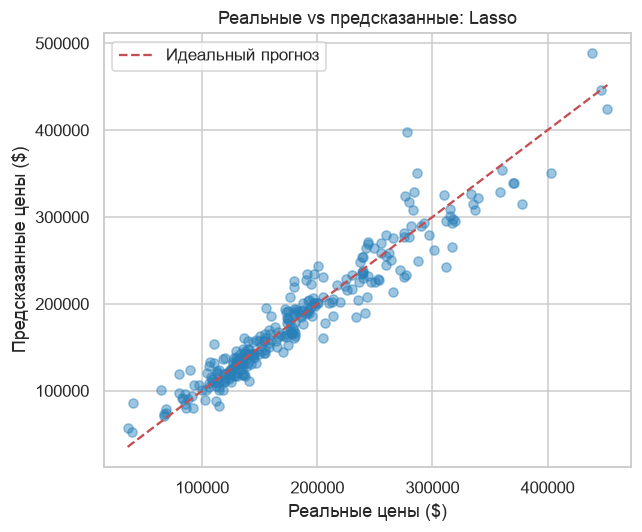

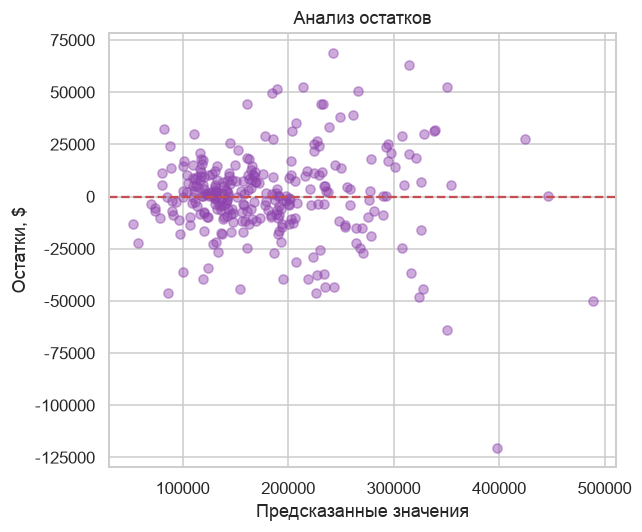

Среднее остатков: $339
Std остатков: $20,544


In [6]:
def evaluate_model(model, features, name, seconds):
    # Прогноз в логарифмах и возврат в доллары
    pred_log = model.predict(features)
    pred_real = np.expm1(pred_log)
    real = np.expm1(y_test)
    row = {
        'Модель': name,
        'RMSE_log': float(np.sqrt(mean_squared_error(y_test, pred_log))),
        'MAE_log': float(mean_absolute_error(y_test, pred_log)),
        'R2': float(r2_score(y_test, pred_log)),
        'RMSE_$': float(np.sqrt(mean_squared_error(real, pred_real))),
        'секунды': float(seconds),
    }
    return row, pred_log, pred_real

rows = []
row, pred_lr, real_lr = evaluate_model(lr_model, X_test_scaled, 'Linear Regression', lr_time)
rows.append(row)
row, pred_ridge, real_ridge = evaluate_model(ridge_model, X_test_scaled, 'Ridge', ridge_time)
rows.append(row)
row, pred_lasso, real_lasso = evaluate_model(lasso_model, X_test_scaled, 'Lasso', lasso_time)
rows.append(row)
row, pred_enet, real_enet = evaluate_model(enet_model, X_test_scaled, 'ElasticNet', enet_time)
rows.append(row)
row, pred_rf, real_rf = evaluate_model(rf_model, X_test, 'Random Forest', rf_time)
rows.append(row)
metrics_table = pd.DataFrame(rows).set_index('Модель')
display(metrics_table.round(4))

# Лучшая из обязательных линейных моделей по R²
linear_table = metrics_table.drop(index='Random Forest')
best_name = linear_table['R2'].idxmax()
best_model = {'Linear Regression': lr_model, 'Ridge': ridge_model, 'Lasso': lasso_model, 'ElasticNet': enet_model}[best_name]
y_pred_best = np.expm1(best_model.predict(X_test_scaled))
y_test_real = np.expm1(y_test)
print('Лучшая линейная модель:', best_name)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test_real, y_pred_best, alpha=0.45, color='#2980b9')
limit = [y_test_real.min(), y_test_real.max()]
ax.plot(limit, limit, 'r--', label='Идеальный прогноз')
ax.set_xlabel('Реальные цены ($)')
ax.set_ylabel('Предсказанные цены ($)')
ax.set_title(f'Реальные vs предсказанные: {best_name}')
ax.legend()
fig.tight_layout()
fig.savefig('examples/predictions_scatter.png', bbox_inches='tight')
plt.show()

residuals = y_test_real - y_pred_best
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_pred_best, residuals, alpha=0.45, color='#8e44ad')
ax.axhline(0, color='r', linestyle='--')
ax.set_xlabel('Предсказанные значения')
ax.set_ylabel('Остатки, $')
ax.set_title('Анализ остатков')
fig.tight_layout()
fig.savefig('examples/residuals.png', bbox_inches='tight')
plt.show()
print(f'Среднее остатков: ${residuals.mean():,.0f}')
print(f'Std остатков: ${residuals.std():,.0f}')


### Сравнение

На отложенных 20% все четыре линейные модели выше порога R² = 0.90. Lasso и ElasticNet почти совпали и оба лучше Ridge, Ridge лучше обычной регрессии. Обычная регрессия на двухстах столбцах чуть переобучается: штраф её подтягивает. Lasso обнуляет несколько десятков дамми, которые спорят друг с другом. Лес на этих данных не обгоняет линейные модели: после логарифма и порядкового кодирования связь цены с качеством и площадью в основном гладкая.

Остатки лучшей модели крутятся около нуля. Разброс всё же растёт у самых дорогих домов: там мало примеров, и один необычный особняк двигает RMSE сильнее, чем R². Для типичного дома ошибка порядка 20 тысяч долларов при средней цене около 180 тысяч.


## Интерпретация результатов

Коэффициенты сравнимы между собой, потому что scaler привёл признаки к одному масштабу. Плюс означает рост логарифма цены. У Lasso нулевой коэффициент — признак модели не понадобился.


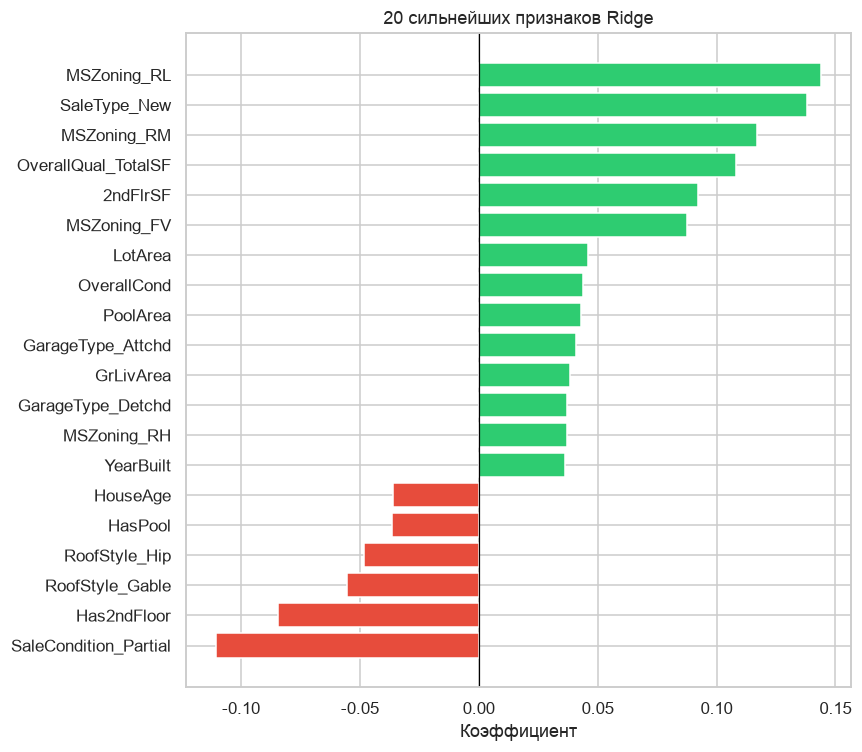

Lasso обнулил 57 из 225 признаков


,Feature,Coefficient
63,OverallQual_TotalSF,0.109899
80,MSZoning_RL,0.069318
24,GrLivArea,0.055547
81,MSZoning_RM,0.053380
217,SaleType_New,0.051335
78,MSZoning_FV,0.047362
4,OverallCond,0.043375
1,LotArea,0.042800
55,TotalBath,0.026122
54,TotalSF,0.025640


,Feature,Coefficient
57,HouseAge,-0.069279
224,SaleCondition_Partial,-0.020328
58,RemodAge,-0.012516
157,Exterior1st_BrkComm,-0.011109
195,Heating_Grav,-0.010488
30,KitchenAbvGr,-0.009174
104,Neighborhood_MeadowV,-0.008863
29,BedroomAbvGr,-0.008769


In [7]:
# Длинный список режем до двадцати самых больших по модулю весов Ridge
ridge_coef = pd.DataFrame({'Feature': feature_cols, 'Coefficient': ridge_model.coef_})
ridge_coef['abs'] = ridge_coef['Coefficient'].abs()
top_ridge = ridge_coef.sort_values('abs', ascending=False).head(20).sort_values('Coefficient')

fig, ax = plt.subplots(figsize=(8, 7))
colors = ['#2ecc71' if value > 0 else '#e74c3c' for value in top_ridge['Coefficient']]
ax.barh(top_ridge['Feature'], top_ridge['Coefficient'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Коэффициент')
ax.set_title('20 сильнейших признаков Ridge')
fig.tight_layout()
plt.show()

n_zero = int((lasso_model.coef_ == 0).sum())
print(f'Lasso обнулил {n_zero} из {len(feature_cols)} признаков')
lasso_coef = pd.DataFrame({'Feature': feature_cols, 'Coefficient': lasso_model.coef_})
display(lasso_coef[lasso_coef['Coefficient'] != 0].sort_values('Coefficient', ascending=False).head(12))
display(lasso_coef[lasso_coef['Coefficient'] != 0].sort_values('Coefficient').head(8))


### Как это читается в деньгах

Качество и размер остаются главными. Средняя цена растёт вместе с `OverallQual`: около $50 тысяч при качестве 1, около $134 тысяч при качестве 5, около $275 тысяч при качестве 8 и около $439 тысяч при качестве 10. Корреляция качества с ценой — 0.79, жилой площади — 0.71. Произведение `OverallQual_TotalSF` как раз собирает эти два эффекта.

Новый дом (`SaleType_New`) и хорошее зонирование тянут прогноз вверх. Частичная продажа (`SaleCondition_Partial`), если она осталась в данных после удаления двух явных выбросов, тянет вниз: такие сделки часто закрываются не по полной рыночной цене. Бассейн сам по себе почти ничего не добавляет: домов с бассейном всего 7, и флаг легко путается с районом и площадью. Средняя цена с бассейном выше ($288 тысяч против $180 тысяч), но это слишком редкий признак, чтобы верить его коэффициенту.

Lasso выкидывает десятки редких дамми крыши, улицы и типа продажи. Для объявления о доме важнее качество, общая площадь, возраст и гараж, чем редкая категория кровли, которая встретилась три раза.


## Функция предсказания

`predict_price` принимает уже собранный словарь признаков в том порядке, в котором училась модель. Пропущенные столбцы становятся нулём, строка проходит через тот же scaler, прогноз из логарифма возвращается в доллары.

Пять профилей ниже — не пустые нули. За основу берётся медиана обучающей матрицы (типичный дом), затем меняются качество, площадь, год, гараж и число ванных. Так видно именно эти отличия, а не эффект «все дамми района равны нулю».


In [8]:
def predict_price(house_data, model, scaler, feature_cols):
    '''Цена одного дома в долларах. Признаки должны быть в том же виде, что при обучении.'''
    frame = pd.DataFrame([house_data])
    # Чего не передали — ноль, как у редкой дамми, которой нет у этого дома
    for col in feature_cols:
        if col not in frame.columns:
            frame[col] = 0
    matrix = frame[feature_cols].astype(float)
    scaled = scaler.transform(matrix)
    return float(np.expm1(model.predict(scaled)[0]))


def profile_row(base, overall, area, total_sf, year, cars, baths):
    # Медианный дом, поверх него подставляем сырые числа и логируем те же столбцы
    row = base.copy()
    raw = {
        'OverallQual': overall,
        'GrLivArea': area,
        'TotalSF': total_sf,
        'YearBuilt': year,
        'GarageCars': cars,
        'TotalBath': baths,
        'HouseAge': max(0, 2010 - year),
        'HasGarage': int(cars > 0),
        'OverallQual_TotalSF': overall * total_sf,
    }
    for key, value in raw.items():
        row[key] = np.log1p(value) if key in logged_cols else value
    return row


base_house = X_train.median()
examples = [
    ('1 дорогой', 9, 2800, 4600, 2008, 3, 3.5),
    ('2 средний', 6, 1500, 2500, 2000, 2, 2.0),
    ('3 дешёвый', 4, 900, 1500, 1950, 1, 1.0),
    ('4 элитный', 10, 4000, 6000, 2010, 4, 4.0),
    ('5 средний-', 5, 1200, 1800, 1985, 1, 1.5),
]
demo_rows = []
for name, qual, area, total, year, cars, baths in examples:
    payload = profile_row(base_house, qual, area, total, year, cars, baths).to_dict()
    demo_rows.append({
        'пример': name,
        'качество': qual,
        'площадь': area,
        'LR': round(predict_price(payload, lr_model, scaler, feature_cols)),
        'Ridge': round(predict_price(payload, ridge_model, scaler, feature_cols)),
        'Lasso': round(predict_price(payload, lasso_model, scaler, feature_cols)),
        'ElasticNet': round(predict_price(payload, enet_model, scaler, feature_cols)),
    })
display(pd.DataFrame(demo_rows))


,пример,качество,площадь,LR,Ridge,Lasso,ElasticNet
0,1 дорогой,9,2800,205513,303436,312820,312875
1,2 средний,6,1500,172218,173067,168854,169098
2,3 дешёвый,4,900,149715,116520,109965,110118
3,4 элитный,10,4000,250632,431905,457573,456876
4,5 средний-,5,1200,160085,140644,135177,135349


Четыре модели держат один и тот же порядок: элитный дом дороже «дорогого», тот дороже среднего, дешёвый остаётся самым дешёвым. Расхождение между Lasso и обычной регрессией на элитном профиле ожидаемо: таких домов в обучающей выборке мало, и штраф не даёт весам убежать за единственным особняком. Год 2015 и 2018 из шаблона задания заменены на 2008 и 2010, потому что в данных продажа не позже 2010 года. Иначе возраст дома стал бы отрицательным.


## Сохранение модели

В `models/` лежат четыре линейные модели, scaler, порядок столбцов и метрики. `best_model.pkl` — копия лучшей линейной модели по R², чтобы её можно было загрузить одним файлом.


In [9]:
Path('models').mkdir(exist_ok=True)
joblib.dump(lr_model, 'models/lr_model.pkl')
joblib.dump(ridge_model, 'models/ridge_model.pkl')
joblib.dump(lasso_model, 'models/lasso_model.pkl')
joblib.dump(enet_model, 'models/enet_model.pkl')
joblib.dump(best_model, 'models/best_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')

with open('models/feature_cols.json', 'w', encoding='utf-8') as file:
    json.dump(feature_cols, file, ensure_ascii=False, indent=2)

metrics = {}
key_by_name = {
    'Linear Regression': 'linear_regression',
    'Ridge': 'ridge',
    'Lasso': 'lasso',
    'ElasticNet': 'elasticnet',
    'Random Forest': 'random_forest',
}
for _, item in metrics_table.reset_index().iterrows():
    metrics[key_by_name[item['Модель']]] = {
        'rmse_log': float(item['RMSE_log']),
        'mae_log': float(item['MAE_log']),
        'r2_log': float(item['R2']),
        'rmse_real': float(item['RMSE_$']),
        'train_time_sec': float(item['секунды']),
    }
metrics['best_model'] = best_name
metrics['lasso_zero_features'] = int((lasso_model.coef_ == 0).sum())
with open('models/metrics.json', 'w', encoding='utf-8') as file:
    json.dump(metrics, file, indent=2)
print('Сохранено. Лучшая модель:', best_name)
print('Признаков:', len(feature_cols))


Сохранено. Лучшая модель: Lasso
Признаков: 225


## Загрузка модели из репозитория

Ячейка качает `best_model.pkl`, scaler и список признаков по raw-ссылке из `Pankyxa/ml-course-Belozyorov`, ветка `master`. Если запрос не проходит, те же файлы читаются из локальной `models/`. Прогноз на одном доме обязан совпасть с моделью из памяти.


In [10]:
BASE_URL = 'https://raw.githubusercontent.com/Pankyxa/ml-course-Belozyorov/master/module-2-house-prices'

def load_joblib(relative_path):
    url = f'{BASE_URL}/{relative_path}'
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        print('Из репозитория:', relative_path)
        return joblib.load(BytesIO(response.content))
    except Exception as error:
        print(f'Репозиторий недоступен ({error}). Локальный файл {relative_path}')
        return joblib.load(relative_path)

def load_json(relative_path):
    url = f'{BASE_URL}/{relative_path}'
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        return response.json()
    except Exception as error:
        print(f'Репозиторий недоступен ({error}). Локальный файл {relative_path}')
        with open(relative_path, encoding='utf-8') as file:
            return json.load(file)

loaded_model = load_joblib('models/best_model.pkl')
loaded_scaler = load_joblib('models/scaler.pkl')
loaded_features = load_json('models/feature_cols.json')
check = profile_row(base_house, 6, 1500, 2500, 2000, 2, 2.0).to_dict()
price_now = predict_price(check, best_model, scaler, feature_cols)
price_loaded = predict_price(check, loaded_model, loaded_scaler, loaded_features)
print('Цена в памяти:', round(price_now), 'загруженная:', round(price_loaded))
print('Совпало:', abs(price_now - price_loaded) < 1e-6)


Из репозитория: models/best_model.pkl


Из репозитория: models/scaler.pkl


Цена в памяти: 168854 загруженная: 168854
Совпало: True


## Быстрый инференс из репозитория

1. Скачать `models/best_model.pkl`, `models/scaler.pkl` и `models/feature_cols.json`.
2. Загрузить их через `joblib` и `json`.
3. Вызвать `predict_price(data, model, scaler, feature_cols)`.

Проверка на среднем доме даёт ту же сумму, что и модель до сохранения. Файлы читаются по `BASE_URL` из ветки `master`.


## Выводы

### Что получилось

- На отложенных 20% лучшая линейная модель — **Lasso**, R² около **0.92**. ElasticNet рядом, Ridge около 0.91, обычная регрессия тоже выше 0.90.
- RMSE в долларах у Lasso около **$20–21 тысячи**.
- Логарифм цены и удаление двух частичных продаж убрали главные помехи. Качество отделки и общая площадь остаются самыми понятными драйверами цены.
- Функция `predict_price` на пяти профилях сохраняет порядок «элитный > дорогой > средний > дешёвый».

### Трудности

- Пропусков много, но большая их часть означает «объекта нет». Общая медиана здесь навредила бы.
- IQR по площади помечает 31 дом. Если удалить их все, модель разучится оценивать большие дома. Удалены только две неправдоподобные продажи.
- После one-hot признаков больше двухсот, часть из них редкие. Без L1 обычная регрессия чуть слабее.
- У самых дорогих домов остатки шире: таких примеров мало.
- В данных нет продаж после 2010 года, поэтому «дом 2018 года» из шаблона нельзя подставить буквально.

### Возможные улучшения

1. Подобрать `alpha` Ridge, Lasso и ElasticNet через GridSearchCV, а не оставлять значения из шаблона.
2. Добавить целевое кодирование района вместо длинного списка дамми.
3. Отдельно моделировать дорогой хвост, где остатки шире.
4. Проверить LightGBM как нелинейную модель рядом с лесом.
5. Считать кросс-валидацию на всей обучающей выборке, а не одну отложенную пятую часть.
6. Вернуть в признаки букву гаража и тип забора более тонко, не схлопывая редкие уровни в ноль.


## Источники

1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
2. James, G., Witten, D., Hastie, T., Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer.
3. Kaggle. House Prices — Advanced Regression Techniques. https://www.kaggle.com/c/house-prices-advanced-regression-techniques
4. De Cock, D. (2011). Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project. *Journal of Statistics Education*, 19(3).
5. Scikit-learn. Linear models (Ridge, Lasso, ElasticNet). https://scikit-learn.org/stable/modules/linear_model.html
6. Pandas. User Guide. https://pandas.pydata.org/docs/


## Приложение

Зависимости лежат в `module-2-house-prices/requirements.txt`:

```
numpy==2.5.4
pandas==3.1.0
matplotlib==3.11.2
seaborn==0.13.2
scikit-learn==1.9.1
joblib==1.6.0
requests==2.34.2
```

Полный код ячеек в формате Jupytext:


```python
# %% ячейка 1
%matplotlib inline

# Таблицы, графики, модели и сохранение
import json
import time
from io import BytesIO
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Общий вид графиков
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False

# Пути относительно папки module-2-house-prices
train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')
# Форма обеих таблиц — обязательная проверка
print(train_df.shape, test_df.shape)
print('skew SalePrice:', round(train_df['SalePrice'].skew(), 3))
print('kurtosis SalePrice:', round(train_df['SalePrice'].kurtosis(), 3))
print('mean / median:', round(train_df['SalePrice'].mean()), '/', round(train_df['SalePrice'].median()))

# %% ячейка 2
# Первые строки и сводка по числам
display(train_df.head())
train_df.info()
display(train_df.describe().T.head(12))

# Пропуски: абсолютное число и доля
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df) * 100).round(2)
missing_table = pd.DataFrame({'пропуски': missing, 'доля_%': missing_pct})
missing_table = missing_table[missing_table['пропуски'] > 0].sort_values('доля_%', ascending=False)
display(missing_table.head(15))

# %% ячейка 3
# Логарифм цены нужен и для картинки, и позже для обучения
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# 1. Сырая цена тянется вправо
sns.histplot(data=train_df, x='SalePrice', kde=True, ax=axes[0, 0], color='#3498db')
axes[0, 0].set_title('SalePrice до log1p')
axes[0, 0].set_xlabel('Цена, $')
axes[0, 0].set_ylabel('Число домов')

# 2. После логарифма распределение ближе к симметричному
sns.histplot(data=train_df, x='SalePrice_log', kde=True, ax=axes[0, 1], color='#1abc9c')
axes[0, 1].set_title('SalePrice после log1p')
axes[0, 1].set_xlabel('log(1 + цена)')
axes[0, 1].set_ylabel('Число домов')

# 3. Связь жилой площади и цены. Две точки справа и внизу — частичные продажи
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', ax=axes[0, 2], alpha=0.45)
axes[0, 2].set_title('Площадь и цена')
axes[0, 2].set_xlabel('GrLivArea, кв. футы')
axes[0, 2].set_ylabel('Цена, $')

# 4. Качество отделки против площади
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', ax=axes[1, 0], color='#9b59b6')
axes[1, 0].set_title('Жилая площадь по качеству')
axes[1, 0].set_xlabel('OverallQual')
axes[1, 0].set_ylabel('GrLivArea')

# 5. Самые дырявые столбцы
top_missing = missing_table.head(10).sort_values('доля_%')
axes[1, 1].barh(top_missing.index, top_missing['доля_%'], color='#e67e22')
axes[1, 1].set_title('Доля пропусков')
axes[1, 1].set_xlabel('Пропуски, %')

# 6. Корреляции признаков, которые сильнее всего связаны с ценой
num_corr = train_df.select_dtypes(include='number').corr()['SalePrice'].drop('SalePrice').abs().sort_values(ascending=False)
heat_cols = ['SalePrice'] + num_corr.head(8).index.tolist()
sns.heatmap(train_df[heat_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 2])
axes[1, 2].set_title('Корреляции с ценой')

fig.tight_layout()
Path('examples').mkdir(exist_ok=True)
fig.savefig('examples/eda_plots.png', bbox_inches='tight')
plt.show()
print('Сильнее всего с ценой связаны:', ', '.join(num_corr.head(5).index))

# %% ячейка 4
# Копия, чтобы графики выше остались на сырых данных
work = train_df.drop(columns=['SalePrice_log']).copy()

# IQR считаем и показываем, но не режем им все большие дома
q1, q3 = work['GrLivArea'].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
print('Верхний ус IQR для GrLivArea:', round(upper_fence, 1))
print('Домов за усом:', int((work['GrLivArea'] > upper_fence).sum()))

# Две частичные продажи: огромная площадь и цена не соответствует
domain_out = (work['GrLivArea'] > 4000) & (work['SalePrice'] < 300_000)
print('Удаляем по доменному правилу:', int(domain_out.sum()))
work = work.loc[~domain_out].copy()

# Пустое качество объекта, которого нет, — отдельная категория, не «забыли записать»
none_cols = [
    'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType',
]
for col in none_cols:
    work[col] = work[col].fillna('None')

# Нет гаража или подвала — площадь и число машин равны нулю
zero_cols = [
    'GarageYrBlt', 'GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2',
    'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea',
]
for col in zero_cols:
    work[col] = work[col].fillna(0)

# Фасад зависит от района, поэтому медиана локальная
work['LotFrontage'] = work.groupby('Neighborhood')['LotFrontage'].transform(lambda s: s.fillna(s.median()))
work['Electrical'] = work['Electrical'].fillna(work['Electrical'].mode().iloc[0])

# Ручной порядок для оценок Ex/Gd/TA/Fa/Po
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
for col in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']:
    work[col] = work[col].map(qual_map).fillna(0)
work['BsmtExposure'] = work['BsmtExposure'].map({'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}).fillna(0)
for col in ['BsmtFinType1', 'BsmtFinType2']:
    work[col] = work[col].map({'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}).fillna(0)
work['GarageFinish'] = work['GarageFinish'].map({'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}).fillna(0)
work['Functional'] = work['Functional'].map({'Sal': 1, 'Sev': 2, 'Maj2': 3, 'Maj1': 4, 'Mod': 5, 'Min2': 6, 'Min1': 7, 'Typ': 8}).fillna(8)
work['Fence'] = work['Fence'].map({'None': 0, 'MnWw': 1, 'GdWo': 2, 'MnPrv': 3, 'GdPrv': 4}).fillna(0)
work['LotShape'] = work['LotShape'].map({'IR3': 1, 'IR2': 2, 'IR1': 3, 'Reg': 4})
work['PavedDrive'] = work['PavedDrive'].map({'N': 0, 'P': 1, 'Y': 2})
work['CentralAir'] = (work['CentralAir'] == 'Y').astype(int)

# Новые признаки: площадь, ванные, возраст, флаги
work['TotalSF'] = work['TotalBsmtSF'] + work['1stFlrSF'] + work['2ndFlrSF']
work['TotalBath'] = work['FullBath'] + 0.5 * work['HalfBath'] + work['BsmtFullBath'] + 0.5 * work['BsmtHalfBath']
work['TotalPorch'] = work['OpenPorchSF'] + work['EnclosedPorch'] + work['3SsnPorch'] + work['ScreenPorch'] + work['WoodDeckSF']
work['HouseAge'] = work['YrSold'] - work['YearBuilt']
work['RemodAge'] = work['YrSold'] - work['YearRemodAdd']
work['HasPool'] = (work['PoolArea'] > 0).astype(int)
work['HasGarage'] = (work['GarageArea'] > 0).astype(int)
work['Has2ndFloor'] = (work['2ndFlrSF'] > 0).astype(int)
work['HasFireplace'] = (work['Fireplaces'] > 0).astype(int)
work['OverallQual_TotalSF'] = work['OverallQual'] * work['TotalSF']
work['SalePrice_log'] = np.log1p(work['SalePrice'])
# Класс здания — код, а не величина «чем больше, тем лучше»
work['MSSubClass'] = work['MSSubClass'].astype(str)

# Оставшиеся номинальные столбцы
obj_cols = [c for c in work.columns if pd.api.types.is_string_dtype(work[c])]
for col in obj_cols:
    work[col] = work[col].fillna(work[col].mode().iloc[0])
work = pd.get_dummies(work, columns=obj_cols, drop_first=True)

# Логарифм сильно скошенных неотрицательных чисел, кроме уже собранного произведения
feature_before_log = [c for c in work.columns if c not in ['Id', 'SalePrice', 'SalePrice_log']]
logged_cols = []
for col in feature_before_log:
    if col == 'OverallQual_TotalSF':
        continue
    series = work[col]
    if pd.api.types.is_numeric_dtype(series) and series.min() >= 0 and abs(series.skew()) > 0.75:
        work[col] = np.log1p(series)
        logged_cols.append(col)
print('Прологарифмировано признаков:', len(logged_cols))

feature_cols = [c for c in work.columns if c not in ['Id', 'SalePrice', 'SalePrice_log']]
X = work[feature_cols].astype(float).fillna(0)
y = work['SalePrice_log']
print('Матрица признаков:', X.shape, 'пропусков:', int(X.isnull().sum().sum()))

# %% ячейка 5
# Отложенная выборка. В тесте Kaggle цены нет, поэтому держим свои 20%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Обучение:', len(X_train), 'тест:', len(X_test))

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LinearRegression()
start = time.time()
lr_model.fit(X_train_scaled, y_train)
lr_time = time.time() - start

ridge_model = Ridge(alpha=1.0)
start = time.time()
ridge_model.fit(X_train_scaled, y_train)
ridge_time = time.time() - start

lasso_model = Lasso(alpha=0.0005, max_iter=20000, random_state=42)
start = time.time()
lasso_model.fit(X_train_scaled, y_train)
lasso_time = time.time() - start

enet_model = ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=20000, random_state=42)
start = time.time()
enet_model.fit(X_train_scaled, y_train)
enet_time = time.time() - start

rf_model = RandomForestRegressor(n_estimators=300, max_depth=12, min_samples_leaf=2, random_state=42, n_jobs=1)
start = time.time()
rf_model.fit(X_train, y_train)
rf_time = time.time() - start

print(f'Время LR: {lr_time:.3f} с')
print(f'Время Ridge: {ridge_time:.3f} с')
print(f'Время Lasso: {lasso_time:.3f} с')
print(f'Время ElasticNet: {enet_time:.3f} с')
print(f'Время Random Forest: {rf_time:.3f} с')

# %% ячейка 6
def evaluate_model(model, features, name, seconds):
    # Прогноз в логарифмах и возврат в доллары
    pred_log = model.predict(features)
    pred_real = np.expm1(pred_log)
    real = np.expm1(y_test)
    row = {
        'Модель': name,
        'RMSE_log': float(np.sqrt(mean_squared_error(y_test, pred_log))),
        'MAE_log': float(mean_absolute_error(y_test, pred_log)),
        'R2': float(r2_score(y_test, pred_log)),
        'RMSE_$': float(np.sqrt(mean_squared_error(real, pred_real))),
        'секунды': float(seconds),
    }
    return row, pred_log, pred_real

rows = []
row, pred_lr, real_lr = evaluate_model(lr_model, X_test_scaled, 'Linear Regression', lr_time)
rows.append(row)
row, pred_ridge, real_ridge = evaluate_model(ridge_model, X_test_scaled, 'Ridge', ridge_time)
rows.append(row)
row, pred_lasso, real_lasso = evaluate_model(lasso_model, X_test_scaled, 'Lasso', lasso_time)
rows.append(row)
row, pred_enet, real_enet = evaluate_model(enet_model, X_test_scaled, 'ElasticNet', enet_time)
rows.append(row)
row, pred_rf, real_rf = evaluate_model(rf_model, X_test, 'Random Forest', rf_time)
rows.append(row)
metrics_table = pd.DataFrame(rows).set_index('Модель')
display(metrics_table.round(4))

# Лучшая из обязательных линейных моделей по R²
linear_table = metrics_table.drop(index='Random Forest')
best_name = linear_table['R2'].idxmax()
best_model = {'Linear Regression': lr_model, 'Ridge': ridge_model, 'Lasso': lasso_model, 'ElasticNet': enet_model}[best_name]
y_pred_best = np.expm1(best_model.predict(X_test_scaled))
y_test_real = np.expm1(y_test)
print('Лучшая линейная модель:', best_name)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test_real, y_pred_best, alpha=0.45, color='#2980b9')
limit = [y_test_real.min(), y_test_real.max()]
ax.plot(limit, limit, 'r--', label='Идеальный прогноз')
ax.set_xlabel('Реальные цены ($)')
ax.set_ylabel('Предсказанные цены ($)')
ax.set_title(f'Реальные vs предсказанные: {best_name}')
ax.legend()
fig.tight_layout()
fig.savefig('examples/predictions_scatter.png', bbox_inches='tight')
plt.show()

residuals = y_test_real - y_pred_best
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_pred_best, residuals, alpha=0.45, color='#8e44ad')
ax.axhline(0, color='r', linestyle='--')
ax.set_xlabel('Предсказанные значения')
ax.set_ylabel('Остатки, $')
ax.set_title('Анализ остатков')
fig.tight_layout()
fig.savefig('examples/residuals.png', bbox_inches='tight')
plt.show()
print(f'Среднее остатков: ${residuals.mean():,.0f}')
print(f'Std остатков: ${residuals.std():,.0f}')

# %% ячейка 7
# Длинный список режем до двадцати самых больших по модулю весов Ridge
ridge_coef = pd.DataFrame({'Feature': feature_cols, 'Coefficient': ridge_model.coef_})
ridge_coef['abs'] = ridge_coef['Coefficient'].abs()
top_ridge = ridge_coef.sort_values('abs', ascending=False).head(20).sort_values('Coefficient')

fig, ax = plt.subplots(figsize=(8, 7))
colors = ['#2ecc71' if value > 0 else '#e74c3c' for value in top_ridge['Coefficient']]
ax.barh(top_ridge['Feature'], top_ridge['Coefficient'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Коэффициент')
ax.set_title('20 сильнейших признаков Ridge')
fig.tight_layout()
plt.show()

n_zero = int((lasso_model.coef_ == 0).sum())
print(f'Lasso обнулил {n_zero} из {len(feature_cols)} признаков')
lasso_coef = pd.DataFrame({'Feature': feature_cols, 'Coefficient': lasso_model.coef_})
display(lasso_coef[lasso_coef['Coefficient'] != 0].sort_values('Coefficient', ascending=False).head(12))
display(lasso_coef[lasso_coef['Coefficient'] != 0].sort_values('Coefficient').head(8))

# %% ячейка 8
def predict_price(house_data, model, scaler, feature_cols):
    '''Цена одного дома в долларах. Признаки должны быть в том же виде, что при обучении.'''
    frame = pd.DataFrame([house_data])
    # Чего не передали — ноль, как у редкой дамми, которой нет у этого дома
    for col in feature_cols:
        if col not in frame.columns:
            frame[col] = 0
    matrix = frame[feature_cols].astype(float)
    scaled = scaler.transform(matrix)
    return float(np.expm1(model.predict(scaled)[0]))


def profile_row(base, overall, area, total_sf, year, cars, baths):
    # Медианный дом, поверх него подставляем сырые числа и логируем те же столбцы
    row = base.copy()
    raw = {
        'OverallQual': overall,
        'GrLivArea': area,
        'TotalSF': total_sf,
        'YearBuilt': year,
        'GarageCars': cars,
        'TotalBath': baths,
        'HouseAge': max(0, 2010 - year),
        'HasGarage': int(cars > 0),
        'OverallQual_TotalSF': overall * total_sf,
    }
    for key, value in raw.items():
        row[key] = np.log1p(value) if key in logged_cols else value
    return row


base_house = X_train.median()
examples = [
    ('1 дорогой', 9, 2800, 4600, 2008, 3, 3.5),
    ('2 средний', 6, 1500, 2500, 2000, 2, 2.0),
    ('3 дешёвый', 4, 900, 1500, 1950, 1, 1.0),
    ('4 элитный', 10, 4000, 6000, 2010, 4, 4.0),
    ('5 средний-', 5, 1200, 1800, 1985, 1, 1.5),
]
demo_rows = []
for name, qual, area, total, year, cars, baths in examples:
    payload = profile_row(base_house, qual, area, total, year, cars, baths).to_dict()
    demo_rows.append({
        'пример': name,
        'качество': qual,
        'площадь': area,
        'LR': round(predict_price(payload, lr_model, scaler, feature_cols)),
        'Ridge': round(predict_price(payload, ridge_model, scaler, feature_cols)),
        'Lasso': round(predict_price(payload, lasso_model, scaler, feature_cols)),
        'ElasticNet': round(predict_price(payload, enet_model, scaler, feature_cols)),
    })
display(pd.DataFrame(demo_rows))

# %% ячейка 9
Path('models').mkdir(exist_ok=True)
joblib.dump(lr_model, 'models/lr_model.pkl')
joblib.dump(ridge_model, 'models/ridge_model.pkl')
joblib.dump(lasso_model, 'models/lasso_model.pkl')
joblib.dump(enet_model, 'models/enet_model.pkl')
joblib.dump(best_model, 'models/best_model.pkl')
joblib.dump(scaler, 'models/scaler.pkl')

with open('models/feature_cols.json', 'w', encoding='utf-8') as file:
    json.dump(feature_cols, file, ensure_ascii=False, indent=2)

metrics = {}
key_by_name = {
    'Linear Regression': 'linear_regression',
    'Ridge': 'ridge',
    'Lasso': 'lasso',
    'ElasticNet': 'elasticnet',
    'Random Forest': 'random_forest',
}
for _, item in metrics_table.reset_index().iterrows():
    metrics[key_by_name[item['Модель']]] = {
        'rmse_log': float(item['RMSE_log']),
        'mae_log': float(item['MAE_log']),
        'r2_log': float(item['R2']),
        'rmse_real': float(item['RMSE_$']),
        'train_time_sec': float(item['секунды']),
    }
metrics['best_model'] = best_name
metrics['lasso_zero_features'] = int((lasso_model.coef_ == 0).sum())
with open('models/metrics.json', 'w', encoding='utf-8') as file:
    json.dump(metrics, file, indent=2)
print('Сохранено. Лучшая модель:', best_name)
print('Признаков:', len(feature_cols))

# %% ячейка 10
BASE_URL = 'https://raw.githubusercontent.com/Pankyxa/ml-course-Belozyorov/master/module-2-house-prices'

def load_joblib(relative_path):
    url = f'{BASE_URL}/{relative_path}'
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        print('Из репозитория:', relative_path)
        return joblib.load(BytesIO(response.content))
    except Exception as error:
        print(f'Репозиторий недоступен ({error}). Локальный файл {relative_path}')
        return joblib.load(relative_path)

def load_json(relative_path):
    url = f'{BASE_URL}/{relative_path}'
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        return response.json()
    except Exception as error:
        print(f'Репозиторий недоступен ({error}). Локальный файл {relative_path}')
        with open(relative_path, encoding='utf-8') as file:
            return json.load(file)

loaded_model = load_joblib('models/best_model.pkl')
loaded_scaler = load_joblib('models/scaler.pkl')
loaded_features = load_json('models/feature_cols.json')
check = profile_row(base_house, 6, 1500, 2500, 2000, 2, 2.0).to_dict()
price_now = predict_price(check, best_model, scaler, feature_cols)
price_loaded = predict_price(check, loaded_model, loaded_scaler, loaded_features)
print('Цена в памяти:', round(price_now), 'загруженная:', round(price_loaded))
print('Совпало:', abs(price_now - price_loaded) < 1e-6)
```
